# Лабораторная работа №3. Исследование решающего дерева

| Задача | Датасет | Модель |
|---|---|---|
| Классификация | GTZAN — жанр по аудиопризнакам (10 классов) | `DecisionTreeClassifier` |
| Регрессия | YearPredictionMSD — год выпуска песни | `DecisionTreeRegressor` |

Датасеты, их обоснование, разбиения train/test и метрики выбраны в ЛР1 (`lab1_knn.ipynb`, раздел 1) и не меняются. Основные метрики: **macro-F1** для классификации и **MAE** (в годах) для регрессии.

**План работы**
1. Кратко о модели.
2. Бейзлайн: дерево sklearn с параметрами по умолчанию.
3. Улучшение бейзлайна: гипотезы → проверка на кросс-валидации → улучшенный бейзлайн.
4. Собственная реализация решающего дерева (CART): сравнение с п. 2 и п. 3.
5. Итоги и сравнение с ЛР1–ЛР2.

Импорты и общие настройки ноутбука

In [1]:
import json, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV, GroupKFold, KFold, cross_val_score, validation_curve
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import FunctionTransformer, QuantileTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))
from src.data import RANDOM_STATE, download_data, gtzan_split, msd_split
from src.results import RESULTS_DIR, classification_metrics, regression_metrics, save_results

warnings.filterwarnings("ignore", category=RuntimeWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 4)
np.random.seed(RANDOM_STATE)

Загружаем данные с теми же фиксированными разбиениями, что и в ЛР1–ЛР2

In [2]:
download_data()
Xc_train, Xc_test, yc_train, yc_test, gc_train, gc_test = gtzan_split()
Xr_train, Xr_test, yr_train, yr_test = msd_split()
print("GTZAN train/test:", Xc_train.shape, Xc_test.shape)
print("MSD   train/test:", Xr_train.shape, Xr_test.shape)

GTZAN train/test: (7993, 57) (1997, 57)
MSD   train/test: (50000, 90) (10000, 90)


## 1. Кратко о модели

Решающее дерево (алгоритм CART) рекурсивно делит пространство признаков на прямоугольные области. В каждом узле перебираются все признаки $j$ и пороги $t$, и выбирается разбиение $x_j \le t$, которое сильнее всего уменьшает **неоднородность** (impurity) дочерних узлов:

$$\text{gain} = n \cdot I(\text{узел}) - n_L \cdot I(\text{левый}) - n_R \cdot I(\text{правый}).$$

* классификация: критерий Джини $I = 1 - \sum_c p_c^2$ или энтропия $I = -\sum_c p_c \log p_c$; в листе — самый частый класс;
* регрессия: дисперсия (MSE) $I = \frac{1}{n}\sum_i (y_i - \bar y)^2$; в листе — среднее значение таргета.

Важные свойства для этой работы:
* **инвариантность к монотонным преобразованиям признаков.** Разбиения зависят только от порядка значений, поэтому масштабирование, логарифмирование и квантильное преобразование признаков дереву не нужны (в отличие от KNN и линейных моделей);
* **разбиения только вдоль осей.** Наклонную границу $x_1 + x_2 \le t$ дерево аппроксимирует «лесенкой» из многих разбиений;
* **склонность к переобучению.** Без ограничений дерево растёт, пока каждый лист не станет чистым, и запоминает обучающую выборку вместе с шумом.

## 2. Создание бейзлайна и оценка качества

Бейзлайн — `DecisionTreeClassifier` / `DecisionTreeRegressor` с параметрами по умолчанию (дерево без ограничений глубины, критерии Джини и MSE) на исходных признаках. `random_state` фиксирован, потому что sklearn перебирает признаки в случайном порядке, и при равном качестве разбиений результат зависит от этого порядка.

Бейзлайн: деревья «из коробки»; смотрим на размер деревьев и качество на train и test

In [3]:
results = {"classification": {}, "regression": {}}
base_clf = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(Xc_train, yc_train)
base_reg = DecisionTreeRegressor(random_state=RANDOM_STATE).fit(Xr_train, yr_train)
results["classification"]["sklearn baseline"] = classification_metrics(yc_test, base_clf.predict(Xc_test))
results["regression"]["sklearn baseline"] = regression_metrics(yr_test, base_reg.predict(Xr_test))
print(f"GTZAN: глубина {base_clf.get_depth()}, листьев {base_clf.get_n_leaves()}, "
      f"macro-F1 на train {classification_metrics(yc_train, base_clf.predict(Xc_train))['f1_macro']:.3f}")
print(f"MSD:   глубина {base_reg.get_depth()}, листьев {base_reg.get_n_leaves()}, "
      f"MAE на train {regression_metrics(yr_train, base_reg.predict(Xr_train))['MAE']:.3f}")
pd.DataFrame(results["classification"]).T, pd.DataFrame(results["regression"]).T

GTZAN: глубина 24, листьев 1331, macro-F1 на train 0.999
MSD:   глубина 39, листьев 34280, MAE на train 0.000


(                  accuracy  f1_macro
 sklearn baseline    0.4852    0.4869,
                      MAE     RMSE      R2
 sklearn baseline  9.6511  14.0326 -0.6611)

**Выводы по бейзлайну.** Оба дерева практически идеально запоминают обучающую выборку (на train macro-F1 ≈ 1, MAE = 0), но плохо обобщают.
* **Классификация:** дерево лучше бейзлайнов KNN и логистической регрессии, потому что не зависит от масштаба признаков. Но оно заметно хуже их улучшенных версий.
* **Регрессия:** MAE хуже даже константного прогноза (8.17). Почти каждая песня обучающей выборки попадает в собственный лист, и прогноз для новой песни — это год одной случайной «похожей» песни, то есть по сути 1-NN с очень грубой метрикой.

## 3. Улучшение бейзлайна

### 3.1. Гипотезы

| № | Гипотеза | Задача |
|---|---|---|
| Г1 | Масштабирование и монотонные преобразования признаков (`StandardScaler`, `QuantileTransformer`) не изменят качество дерева | обе |
| Г2 | Ограничение сложности дерева (`max_depth`, `min_samples_leaf`) уменьшит переобучение | обе |
| Г3 | Пост-прунинг (cost-complexity pruning, `ccp_alpha`) уменьшит переобучение | обе |
| Г4 | Поворот признакового пространства (PCA) упростит разбиения вдоль осей | обе |
| Г5 | Добавление проекций с учителем — компонент LDA (классификация) или PLS (регрессия) — даст дереву «наклонные» разбиения по информативным линейным комбинациям признаков | обе |
| Г6 | Логарифмирование таргета `log(2012 − year)`, которое помогло в ЛР2, поможет и дереву | регрессия |

Гипотезы проверяются на кросс-валидации по train с теми же фолдами, что и в ЛР1–ЛР2. Тестовая выборка используется только для итоговой оценки.

Функции оценки на кросс-валидации: средний macro-F1 (GTZAN) и средний MAE (MSD) по 5 фолдам

In [4]:
cv_c = GroupKFold(n_splits=5)
cv_r = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_clf(model):
    return cross_val_score(model, Xc_train, yc_train, cv=cv_c, groups=gc_train, scoring="f1_macro", n_jobs=5).mean()

def cv_reg(model):
    return -cross_val_score(model, Xr_train, yr_train, cv=cv_r, scoring="neg_mean_absolute_error", n_jobs=5).mean()

QT = lambda: QuantileTransformer(output_distribution="normal", random_state=RANDOM_STATE)
DTC = lambda **kw: DecisionTreeClassifier(random_state=RANDOM_STATE, **kw)
DTR = lambda **kw: DecisionTreeRegressor(random_state=RANDOM_STATE, **kw)
hyp_c = {"бейзлайн": cv_clf(DTC())}
hyp_r = {"бейзлайн": cv_reg(DTR())}

#### Г1. Масштабирование и монотонные преобразования признаков

Дерево после StandardScaler и QuantileTransformer

In [5]:
for name, prep in [("StandardScaler", StandardScaler()), ("QuantileTransformer", QT())]:
    hyp_c[f"Г1: {name}"] = cv_clf(Pipeline([("prep", prep), ("tree", DTC())]))
    hyp_r[f"Г1: {name}"] = cv_reg(Pipeline([("prep", clone(prep)), ("tree", DTR())]))
pd.DataFrame({"GTZAN macro-F1 ↑": hyp_c, "MSD MAE ↓": hyp_r})

,GTZAN macro-F1 ↑,MSD MAE ↓
бейзлайн,0.5140,9.3525
Г1: StandardScaler,0.5120,9.3579
Г1: QuantileTransformer,0.5112,9.3742


**Г1 подтверждена.** Монотонные преобразования не меняют порядок значений признака, поэтому набор возможных разбиений остаётся тем же, и качество практически не меняется: различия в третьем знаке, в обе стороны. Небольшие отличия всё же есть. Дерево хранит признаки в `float32`, и после преобразования часть очень близких значений начинает совпадать или различаться иначе. `QuantileTransformer` к тому же интерполирует по 1000 квантилям и «склеивает» близкие значения. Это меняет выбор между почти равноценными разбиениями в глубоких узлах неограниченного дерева. Систематического выигрыша нет: предобработка, которая была ключевой для KNN и линейных моделей, дереву не нужна.

#### Г2. Ограничение сложности дерева

Кривые обучения по глубине: качество на train и на кросс-валидации

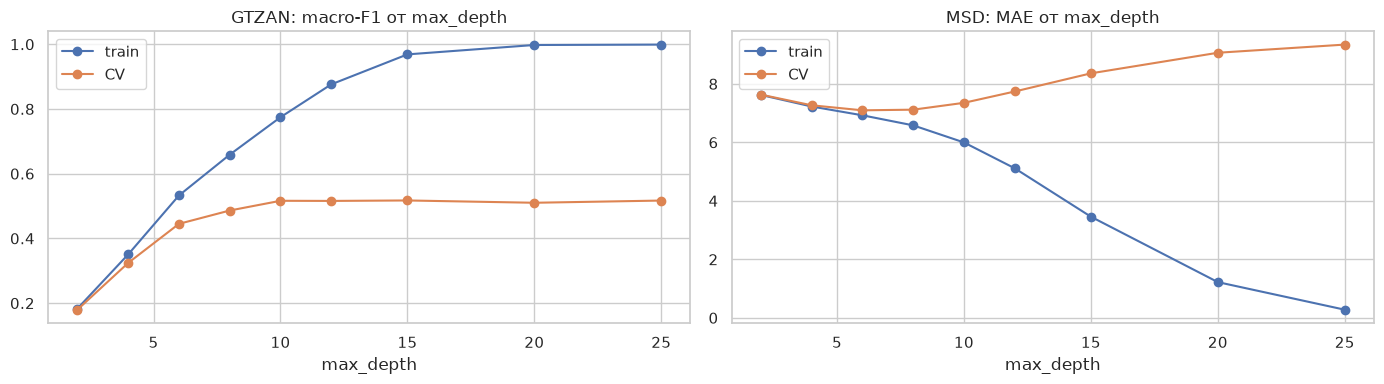

In [6]:
depths = [2, 4, 6, 8, 10, 12, 15, 20, 25]
tr_c, va_c = validation_curve(DTC(), Xc_train, yc_train, param_name="max_depth", param_range=depths,
                              cv=cv_c, groups=gc_train, scoring="f1_macro", n_jobs=5)
tr_r, va_r = validation_curve(DTR(), Xr_train, yr_train, param_name="max_depth", param_range=depths,
                              cv=cv_r, scoring="neg_mean_absolute_error", n_jobs=5)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(depths, tr_c.mean(1), marker="o", label="train"); axes[0].plot(depths, va_c.mean(1), marker="o", label="CV")
axes[0].set_title("GTZAN: macro-F1 от max_depth"); axes[0].set_xlabel("max_depth"); axes[0].legend()
axes[1].plot(depths, -tr_r.mean(1), marker="o", label="train"); axes[1].plot(depths, -va_r.mean(1), marker="o", label="CV")
axes[1].set_title("MSD: MAE от max_depth"); axes[1].set_xlabel("max_depth"); axes[1].legend()
plt.tight_layout(); plt.show()

Минимальное число объектов в листе

In [7]:
for leaf in [5, 20]:
    hyp_c[f"Г2: min_samples_leaf={leaf}"] = cv_clf(DTC(min_samples_leaf=leaf))
for leaf in [50, 200, 400]:
    hyp_r[f"Г2: min_samples_leaf={leaf}"] = cv_reg(DTR(min_samples_leaf=leaf))
hyp_c["Г2: max_depth=10"] = va_c.mean(1)[depths.index(10)]
hyp_r["Г2: max_depth=6"] = -va_r.mean(1)[depths.index(6)]
pd.DataFrame({"GTZAN macro-F1 ↑": hyp_c, "MSD MAE ↓": hyp_r})

,GTZAN macro-F1 ↑,MSD MAE ↓
бейзлайн,0.5140,9.3525
Г1: StandardScaler,0.5120,9.3579
Г1: QuantileTransformer,0.5112,9.3742
Г2: min_samples_leaf=5,0.5204,NaN
Г2: min_samples_leaf=20,0.5120,NaN
Г2: max_depth=10,0.5162,NaN
Г2: min_samples_leaf=50,NaN,7.1741
Г2: min_samples_leaf=200,NaN,7.0109
Г2: min_samples_leaf=400,NaN,7.0499
Г2: max_depth=6,NaN,7.0949


**Г2 подтверждена для регрессии и почти не влияет на классификацию.**
* **MSD:** классическая картина переобучения. Ошибка на train падает с ростом глубины, а на CV — сначала падает, затем растёт. Оптимум — неглубокое дерево (глубина около 6) или крупные листья (сотни объектов). Год выпуска — сильно зашумлённая величина, и надёжная оценка получается только усреднением по большой группе песен. Ограничение сложности даёт самый большой прирост.
* **GTZAN:** после глубины ~10 качество на CV выходит на плато, а ограничение листьев почти ничего не меняет. Классы здесь хорошо разделимы, шум меньше, а глубокие ветви «разрастаются» на малых подвыборках и почти не влияют на прогноз. Предел качества одного дерева связан не с переобучением, а с грубостью кусочно-постоянной границы вдоль осей.

#### Г3. Пост-прунинг (cost-complexity pruning)

Строим полное дерево и обрезаем ветви, прирост качества которых меньше ccp_alpha на каждый дополнительный лист

In [8]:
for a in [0.0005, 0.001, 0.002, 0.005]:
    hyp_c[f"Г3: ccp_alpha={a}"] = cv_clf(DTC(ccp_alpha=a))
for a in [0.05, 0.1, 0.2]:
    hyp_r[f"Г3: ccp_alpha={a}"] = cv_reg(DTR(ccp_alpha=a))
pd.DataFrame({"GTZAN macro-F1 ↑": hyp_c, "MSD MAE ↓": hyp_r})

,GTZAN macro-F1 ↑,MSD MAE ↓
бейзлайн,0.5140,9.3525
Г1: StandardScaler,0.5120,9.3579
Г1: QuantileTransformer,0.5112,9.3742
Г2: min_samples_leaf=5,0.5204,NaN
Г2: min_samples_leaf=20,0.5120,NaN
Г2: max_depth=10,0.5162,NaN
Г3: ccp_alpha=0.0005,0.5258,NaN
Г3: ccp_alpha=0.001,0.5189,NaN
Г3: ccp_alpha=0.002,0.4977,NaN
Г3: ccp_alpha=0.005,0.4203,NaN


**Г3: результат на уровне Г2.** Пост-прунинг даёт примерно то же качество, что и простые ограничения `max_depth` / `min_samples_leaf`. Для GTZAN слабый прунинг (`ccp_alpha=0.0005`) даёт +1 п.п. к лучшему варианту Г2, а более сильный быстро ухудшает качество. Для MSD лучший `ccp_alpha` немного уступает `min_samples_leaf=200`. Выигрыш в пределах разброса оценки, поэтому дальше используем предварительные ограничения (pre-pruning) в сочетании с другими гипотезами. Их проще подбирать по сетке, и они же реализованы в собственном дереве.

#### Г4. Поворот признакового пространства (PCA)

PCA на стандартизированных признаках: дерево делит по главным компонентам вместо исходных признаков

In [9]:
hyp_c["Г4: PCA"] = cv_clf(Pipeline([("sc", StandardScaler()), ("pca", PCA(random_state=RANDOM_STATE)), ("tree", DTC(min_samples_leaf=20))]))
hyp_r["Г4: PCA"] = cv_reg(Pipeline([("sc", StandardScaler()), ("pca", PCA(random_state=RANDOM_STATE)), ("tree", DTR(min_samples_leaf=200))]))
pd.DataFrame({"GTZAN macro-F1 ↑": hyp_c, "MSD MAE ↓": hyp_r})

,GTZAN macro-F1 ↑,MSD MAE ↓
бейзлайн,0.5140,9.3525
Г1: StandardScaler,0.5120,9.3579
Г1: QuantileTransformer,0.5112,9.3742
Г2: min_samples_leaf=5,0.5204,NaN
Г2: min_samples_leaf=20,0.5120,NaN
Г2: max_depth=10,0.5162,NaN
Г3: ccp_alpha=0.0005,0.5258,NaN
Г3: ccp_alpha=0.001,0.5189,NaN
Г3: ccp_alpha=0.002,0.4977,NaN
Г3: ccp_alpha=0.005,0.4203,NaN


**Г4 не подтвердилась.** Главные компоненты выбираются по дисперсии признаков, а не по связи с целевой переменной. Каждая компонента «размазывает» информацию по всем признакам, и разбиения по ним хуже, чем по исходным интерпретируемым характеристикам.

#### Г5. Признаки-проекции с учителем: LDA и PLS

В отличие от PCA, LDA (линейный дискриминантный анализ) ищет линейные комбинации признаков, которые лучше всего **разделяют классы**, а PLS (метод частичных наименьших квадратов) — комбинации, наиболее **связанные с таргетом**. Добавим эти проекции к исходным признакам (`FeatureUnion`): тогда дерево сможет выбирать и разбиения по осям, и «наклонные» разбиения по проекциям. Проекции обучаются только на train-части каждого фолда (внутри `Pipeline`), поэтому утечки нет.

Вспомогательные конструкторы признаков: исходные признаки + 9 компонент LDA (число классов − 1) или исходные признаки + k компонент PLS (компоненты PLS считаются на стандартизированных признаках).

In [10]:
class PLSFeatures(BaseEstimator, TransformerMixin):
    """Компоненты PLS как признаки (PLSRegression.fit_transform возвращает пару, поэтому нужна обёртка)."""

    def __init__(self, n_components=10):
        self.n_components = n_components

    def fit(self, X, y):
        self.pls_ = PLSRegression(n_components=self.n_components, scale=False).fit(X, y)
        return self

    def transform(self, X):
        return self.pls_.transform(X)


def with_lda():
    return FeatureUnion([("orig", FunctionTransformer()), ("lda", LinearDiscriminantAnalysis())])


def with_pls(k=10):
    return FeatureUnion([("orig", FunctionTransformer()), ("pls", Pipeline([("sc", StandardScaler()), ("pls", PLSFeatures(k))]))])

Проверяем добавление проекций

In [11]:
hyp_c["Г5: + LDA, min_samples_leaf=5"] = cv_clf(Pipeline([("feat", with_lda()), ("tree", DTC(min_samples_leaf=5))]))
for k in [3, 10]:
    hyp_r[f"Г5: + PLS({k}), min_samples_leaf=200"] = cv_reg(Pipeline([("feat", with_pls(k)), ("tree", DTR(min_samples_leaf=200))]))
pd.DataFrame({"GTZAN macro-F1 ↑": hyp_c, "MSD MAE ↓": hyp_r})

,GTZAN macro-F1 ↑,MSD MAE ↓
бейзлайн,0.5140,9.3525
Г1: StandardScaler,0.5120,9.3579
Г1: QuantileTransformer,0.5112,9.3742
Г2: min_samples_leaf=5,0.5204,NaN
Г2: min_samples_leaf=20,0.5120,NaN
Г2: max_depth=10,0.5162,NaN
Г3: ccp_alpha=0.0005,0.5258,NaN
Г3: ccp_alpha=0.001,0.5189,NaN
Г3: ccp_alpha=0.002,0.4977,NaN
Г3: ccp_alpha=0.005,0.4203,NaN


**Г5 подтверждена для обеих задач.** Проекции с учителем дают лучший прирост среди всех гипотез. Дерево использует их в верхних узлах: одно разбиение по компоненте LDA или PLS заменяет «лесенку» из многих разбиений по исходным признакам. Освободившаяся глубина тратится на уточнение. По сути получается простая версия «наклонного» дерева (oblique tree).

#### Г6. Логарифмирование таргета

Дерево обучается на log(2012 - year), прогноз переводится обратно в год

In [12]:
log_y = lambda y: np.log(2012 - y)
exp_y = lambda z: 2012 - np.exp(z)
log_target = lambda model: TransformedTargetRegressor(regressor=model, func=log_y, inverse_func=exp_y)
hyp_r["Г6: log-таргет, min_samples_leaf=200"] = cv_reg(log_target(DTR(min_samples_leaf=200)))
hyp_r["Г5+Г6: + PLS(10), log-таргет"] = cv_reg(log_target(Pipeline([("feat", with_pls(10)), ("tree", DTR(min_samples_leaf=200))])))
pd.Series(hyp_r, name="MSD MAE ↓").to_frame()

,MSD MAE ↓
бейзлайн,9.3525
Г1: StandardScaler,9.3579
Г1: QuantileTransformer,9.3742
Г2: min_samples_leaf=50,7.1741
Г2: min_samples_leaf=200,7.0109
Г2: min_samples_leaf=400,7.0499
Г2: max_depth=6,7.0949
Г3: ccp_alpha=0.05,7.2801
Г3: ccp_alpha=0.1,7.0919
Г3: ccp_alpha=0.2,7.1498


**Г6 подтверждена.** Для дерева логарифмирование таргета меняет то, что усредняется в листе. Лист предсказывает $2012 - \exp(\text{среднее}\ \log(2012 - y))$, то есть «геометрическое» среднее расстояния до 2012 года. Оно ближе к медиане, чем арифметическое, и меньше смещается редкими старыми записями. Поэтому MAE (а он минимизируется медианой) снижается. Вместе с PLS-признаками получается лучший результат.

### 3.2. Подбор гиперпараметров и улучшенный бейзлайн

Перебираем по сетке на кросс-валидации:
* **классификация:** признаки (исходные / + LDA), критерий (gini / entropy), `max_depth`, `min_samples_leaf`;
* **регрессия** (с логарифмированием таргета и PLS-признаками): число компонент PLS, `max_depth`, `min_samples_leaf`.

Сетка для классификации (GroupKFold по трекам, macro-F1)

In [13]:
grid_c = GridSearchCV(Pipeline([("feat", "passthrough"), ("tree", DTC())]), {
    "feat": ["passthrough", with_lda()],
    "tree__criterion": ["gini", "entropy"],
    "tree__max_depth": [None, 8, 10, 12, 15],
    "tree__min_samples_leaf": [1, 2, 5, 10, 20],
}, cv=cv_c, scoring="f1_macro", n_jobs=6)
t0 = time.time(); grid_c.fit(Xc_train, yc_train, groups=gc_train)
print(f"{time.time() - t0:.0f} c | лучшие параметры: {grid_c.best_params_} | CV macro-F1 = {grid_c.best_score_:.4f}")
hyp_c["GridSearchCV"] = grid_c.best_score_

54 c | лучшие параметры: {'feat': FeatureUnion(transformer_list=[('orig', FunctionTransformer()),
                               ('lda', LinearDiscriminantAnalysis())]), 'tree__criterion': 'entropy', 'tree__max_depth': 10, 'tree__min_samples_leaf': 5} | CV macro-F1 = 0.5684


Сетка для регрессии (KFold, MAE)

In [14]:
grid_r = GridSearchCV(log_target(Pipeline([("feat", with_pls()), ("tree", DTR())])), {
    "regressor__feat__pls__pls__n_components": [3, 10, 20],
    "regressor__tree__max_depth": [None, 8, 12],
    "regressor__tree__min_samples_leaf": [50, 100, 200, 400],
}, cv=cv_r, scoring="neg_mean_absolute_error", n_jobs=6)
t0 = time.time(); grid_r.fit(Xr_train, yr_train)
print(f"{time.time() - t0:.0f} c | лучшие параметры: {grid_r.best_params_} | CV MAE = {-grid_r.best_score_:.4f}")
hyp_r["GridSearchCV"] = -grid_r.best_score_

218 c | лучшие параметры: {'regressor__feat__pls__pls__n_components': 20, 'regressor__tree__max_depth': 8, 'regressor__tree__min_samples_leaf': 200} | CV MAE = 6.4373


Сводка проверки всех гипотез на кросс-валидации

In [15]:
pd.concat([pd.Series(hyp_c, name="GTZAN CV macro-F1 ↑"), pd.Series(hyp_r, name="MSD CV MAE ↓")], axis=1)

,GTZAN CV macro-F1 ↑,MSD CV MAE ↓
бейзлайн,0.5140,9.3525
Г1: StandardScaler,0.5120,9.3579
Г1: QuantileTransformer,0.5112,9.3742
Г2: min_samples_leaf=5,0.5204,NaN
Г2: min_samples_leaf=20,0.5120,NaN
Г2: max_depth=10,0.5162,NaN
Г3: ccp_alpha=0.0005,0.5258,NaN
Г3: ccp_alpha=0.001,0.5189,NaN
Г3: ccp_alpha=0.002,0.4977,NaN
Г3: ccp_alpha=0.005,0.4203,NaN


Улучшенный бейзлайн: лучшие конвейеры из GridSearchCV (уже переобучены на всём train), оценка на test

In [16]:
best_clf, best_reg = grid_c.best_estimator_, grid_r.best_estimator_
yc_pred_best, yr_pred_best = best_clf.predict(Xc_test), best_reg.predict(Xr_test)
results["classification"]["sklearn improved"] = classification_metrics(yc_test, yc_pred_best)
results["regression"]["sklearn improved"] = regression_metrics(yr_test, yr_pred_best)
tree_c, tree_r = best_clf[-1], best_reg.regressor_[-1]
print(f"GTZAN: глубина {tree_c.get_depth()}, листьев {tree_c.get_n_leaves()} | MSD: глубина {tree_r.get_depth()}, листьев {tree_r.get_n_leaves()}")
pd.DataFrame(results["classification"]).T, pd.DataFrame(results["regression"]).T

GTZAN: глубина 10, листьев 403 | MSD: глубина 8, листьев 136


(                  accuracy  f1_macro
 sklearn baseline    0.4852    0.4869
 sklearn improved    0.5338    0.5314,
                      MAE     RMSE      R2
 sklearn baseline  9.6511  14.0326 -0.6611
 sklearn improved  6.4885   9.8552  0.1807)

Важность признаков (суммарное уменьшение неоднородности по всем разбиениям признака) для улучшенных деревьев

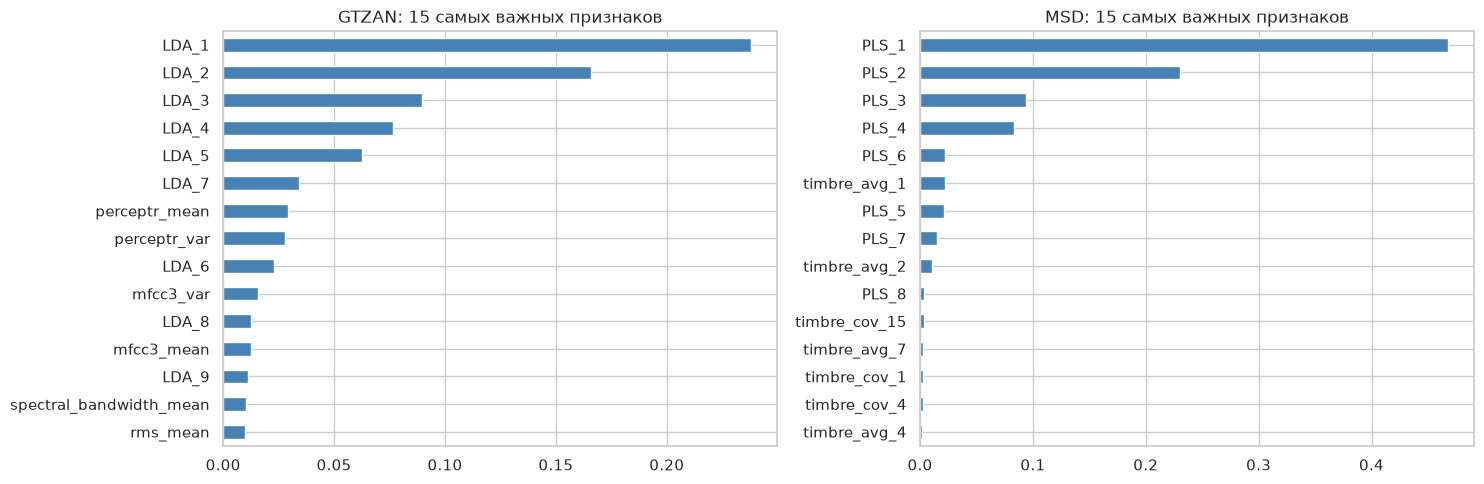

In [17]:
names_c = list(Xc_train.columns) + [f"LDA_{i + 1}" for i in range(tree_c.n_features_in_ - Xc_train.shape[1])]
names_r = list(Xr_train.columns) + [f"PLS_{i + 1}" for i in range(tree_r.n_features_in_ - Xr_train.shape[1])]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, tree, names, title in [(axes[0], tree_c, names_c, "GTZAN"), (axes[1], tree_r, names_r, "MSD")]:
    pd.Series(tree.feature_importances_, index=names).nlargest(15).sort_values().plot.barh(ax=ax, color="steelblue")
    ax.set_title(f"{title}: 15 самых важных признаков")
plt.tight_layout(); plt.show()

Верхние уровни улучшенного дерева регрессии: дерево интерпретируемо — видно, по каким признакам и порогам оно делит песни

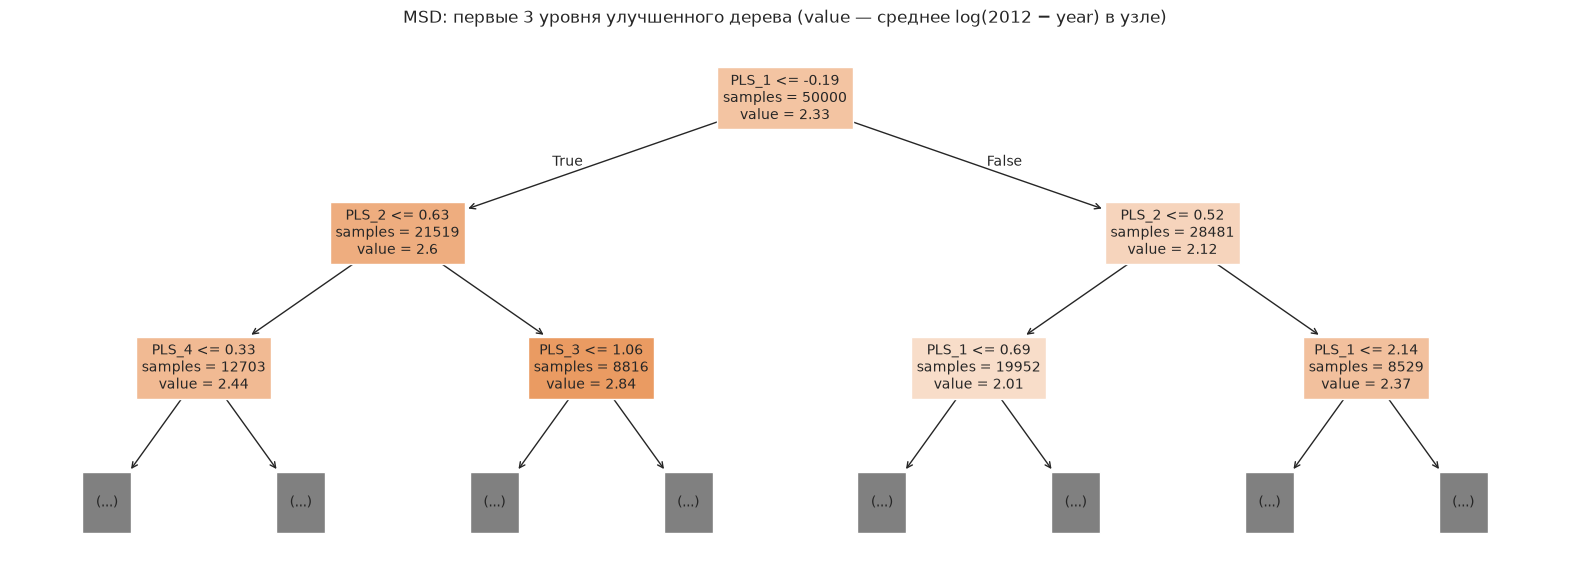

In [18]:
plt.figure(figsize=(20, 7))
plot_tree(tree_r, max_depth=2, feature_names=names_r, filled=True, impurity=False, precision=2, fontsize=10)
plt.title("MSD: первые 3 уровня улучшенного дерева (value — среднее log(2012 − year) в узле)")
plt.show()

Матрица ошибок улучшенного классификатора

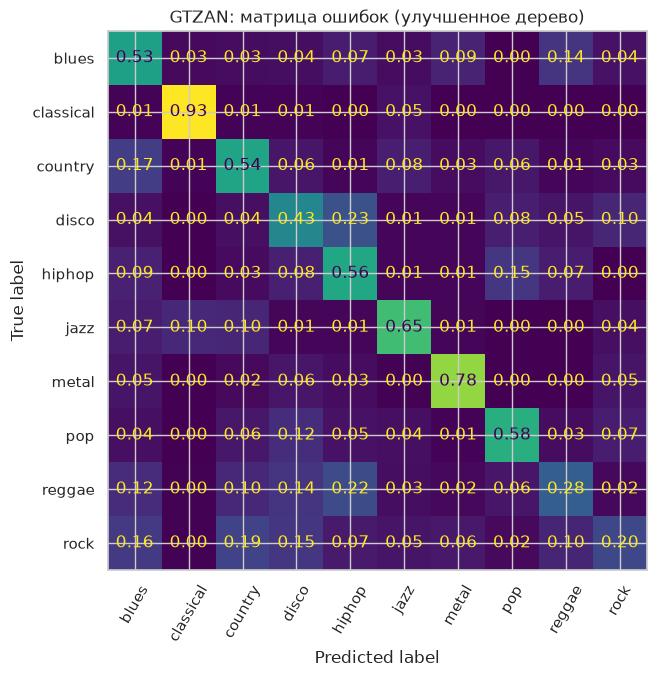

In [19]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(yc_test, yc_pred_best, normalize="true", values_format=".2f", ax=ax, colorbar=False, xticks_rotation=60)
ax.set_title("GTZAN: матрица ошибок (улучшенное дерево)"); plt.show()

**Выводы по улучшенному бейзлайну (сравнение с п. 2).**
* **Классификация:** прирост умеренный (около +4.5 п.п. macro-F1 на тесте). Ограничение сложности для GTZAN почти не помогает, основной вклад дают LDA-признаки: на них приходится большая часть важности признаков в дереве. Одиночное дерево остаётся заметно слабее KNN и логистической регрессии: кусочно-постоянная граница вдоль осей плохо описывает плавные различия между похожими жанрами.
* **Регрессия:** MAE снизился очень сильно — с уровня хуже константы до результата лучше KNN. Главный вклад даёт ограничение сложности (глубина 8, не меньше 200 песен в листе), дополнительный — PLS-признаки и логарифмирование таргета. Два верхних уровня дерева строятся только по компонентам PLS. Среди исходных признаков самые важные — средние значения тембра (`timbre_avg_1`, `timbre_avg_2`), что согласуется с ЛР2.

## 4. Имплементация алгоритма

### 4.1. Собственная реализация CART

Дерево строится жадно, сверху вниз, с помощью стека узлов. Для каждого узла:
1. если достигнута `max_depth`, в узле меньше `min_samples_split` объектов или он чистый — узел становится листом;
2. иначе для **всех признаков сразу** ищется лучший порог:
   * объекты узла сортируются по каждому признаку (`argsort` по столбцам матрицы);
   * для каждой позиции разреза накопленными суммами (`cumsum`) считаются статистики левой и правой частей: число объектов каждого класса (классификация) или сумма $y$ и $y^2$ (регрессия);
   * из них за $O(1)$ на позицию считается взвешенная неоднородность детей. Так все пороги всех признаков проверяются за $O(n \cdot d)$ после сортировки, без Python-циклов по порогам;
   * разрезы между одинаковыми (с точностью до $10^{-7}$, как в sklearn) значениями и разрезы, оставляющие в листе меньше `min_samples_leaf` объектов, исключаются;
3. порог — середина между соседними различными значениями, как в sklearn.

Для минимизации взвешенной неоднородности используются эквивалентные формулы:
* Джини: $n_L I_L + n_R I_R = n - \sum_c \frac{c_{L,c}^2}{n_L} - \sum_c \frac{c_{R,c}^2}{n_R}$;
* энтропия: $n_L I_L = n_L \log n_L - \sum_c c_{L,c} \log c_{L,c}$;
* MSE: $n_L I_L = \sum_L y^2 - \frac{(\sum_L y)^2}{n_L}$.

Как и sklearn, признаки приводятся к `float32` перед поиском порогов. Предсказание для всех объектов выполняется векторно: на каждом шаге все объекты, ещё не дошедшие до листа, переходят в левого или правого потомка.

Реализация: класс `MyDecisionTree` для классификации и регрессии. Дерево хранится в виде параллельных массивов (признак, порог, левый и правый потомок, значение в узле); `feature = -1` означает лист.

Детали реализации:
* `_best_split` возвращает признак, порог, взвешенную неоднородность детей и индексы объектов, ушедших влево и вправо. Отсортированный порядок объектов уже посчитан, поэтому разделение узла не требует повторного сравнения;
* `feature_importances_` — как в sklearn: сумма уменьшений неоднородности $n I - n_L I_L - n_R I_R$ по всем разбиениям признака, нормированная на 1;
* значение в листе — доли классов (для `predict` берётся класс с наибольшей долей, при равенстве — первый по алфавиту, как в sklearn) или среднее таргета;
* узлы обрабатываются в порядке обхода в глубину (сначала левый потомок), как в sklearn;
* после обучения обучающая выборка удаляется из объекта (`del self.X_`), остаются только массивы дерева.

In [20]:
class MyDecisionTree:
    """CART для классификации (criterion = 'gini' | 'entropy') и регрессии (criterion = 'mse')."""

    def __init__(self, criterion="gini", max_depth=None, min_samples_split=2, min_samples_leaf=1):
        self.criterion, self.max_depth = criterion, max_depth
        self.min_samples_split, self.min_samples_leaf = min_samples_split, min_samples_leaf

    def _node_impurity_sum(self, stats, n):
        if self.criterion == "mse":
            s, s2 = stats
            return s2 - s ** 2 / n
        counts = stats
        if self.criterion == "gini":
            return n - (counts ** 2).sum(axis=-1) / n
        with np.errstate(divide="ignore", invalid="ignore"):
            plogp = np.where(counts > 0, counts * np.log(counts), 0.0).sum(axis=-1)
        return n * np.log(n) - plogp

    def _best_split(self, idx):
        X, n, leaf = self.X_[idx], len(idx), self.min_samples_leaf
        order = np.argsort(X, axis=0, kind="stable")
        Xs = np.take_along_axis(X, order, axis=0)
        n_left = np.arange(1, n)[:, None]
        if self.criterion == "mse":
            ys = self.y_[idx][order]
            cs, cs2 = np.cumsum(ys, axis=0), np.cumsum(ys ** 2, axis=0)
            left = (cs[:-1], cs2[:-1])
            right = (cs[-1] - cs[:-1], cs2[-1] - cs2[:-1])
            n_l, n_r = n_left, n - n_left
        else:
            Ys = self.Y_[idx][order]
            cc = np.cumsum(Ys, axis=0)
            left, right = cc[:-1], cc[-1] - cc[:-1]
            n_l, n_r = n_left, n - n_left
        cost = self._node_impurity_sum(left, n_l) + self._node_impurity_sum(right, n_r)
        valid = (Xs[1:] > Xs[:-1].astype(np.float64) + 1e-7) & (n_left >= leaf) & (n - n_left >= leaf)
        if not valid.any():
            return None
        cost = np.where(valid, cost, np.inf)
        pos, feat = np.unravel_index(np.argmin(cost), cost.shape)
        lo, hi = float(Xs[pos, feat]), float(Xs[pos + 1, feat])
        thr = lo / 2.0 + hi / 2.0
        if thr == hi or not np.isfinite(thr):
            thr = lo
        return feat, float(thr), cost[pos, feat], order[: pos + 1, feat], order[pos + 1:, feat]

    def _leaf_value(self, idx):
        if self.criterion == "mse":
            return np.array([self.y_[idx].mean()])
        return self.Y_[idx].sum(axis=0) / len(idx)

    def fit(self, X, y):
        self.X_ = np.asarray(X, dtype=np.float32)
        if self.criterion == "mse":
            self.y_ = np.asarray(y, dtype=np.float64)
        else:
            self.classes_, codes = np.unique(y, return_inverse=True)
            self.Y_ = np.eye(len(self.classes_))[codes]
        n_features = self.X_.shape[1]
        self.feature, self.threshold, self.left, self.right, self.value = [], [], [], [], []
        self.feature_importances_ = np.zeros(n_features)
        stack = [(np.arange(len(self.X_)), 0, None, None)]
        while stack:
            idx, depth, parent, is_left = stack.pop()
            node = len(self.feature)
            self.feature.append(-1); self.threshold.append(0.0); self.left.append(-1); self.right.append(-1)
            self.value.append(self._leaf_value(idx))
            if parent is not None:
                (self.left if is_left else self.right)[parent] = node
            if self.criterion == "mse":
                impurity_sum = len(idx) * self.y_[idx].var()
            else:
                impurity_sum = self._node_impurity_sum(self.Y_[idx].sum(axis=0), len(idx))
            if ((self.max_depth is not None and depth >= self.max_depth) or len(idx) < self.min_samples_split
                    or len(idx) < 2 * self.min_samples_leaf or impurity_sum <= 1e-12):
                continue
            split = self._best_split(idx)
            if split is None:
                continue
            feat, thr, cost, li, ri = split
            self.feature[node], self.threshold[node] = int(feat), thr
            self.feature_importances_[feat] += impurity_sum - cost
            stack.append((idx[ri], depth + 1, node, False))
            stack.append((idx[li], depth + 1, node, True))
        self.feature, self.threshold = np.array(self.feature), np.array(self.threshold)
        self.left, self.right, self.value = np.array(self.left), np.array(self.right), np.array(self.value)
        self.feature_importances_ /= max(self.feature_importances_.sum(), 1e-12)
        del self.X_
        return self

    def apply(self, X):
        X = np.asarray(X, dtype=np.float32)
        node = np.zeros(len(X), dtype=np.int64)
        active = self.feature[node] >= 0
        while active.any():
            a = np.where(active)[0]
            f = self.feature[node[a]]
            go_left = X[a, f] <= self.threshold[node[a]]
            node[a] = np.where(go_left, self.left[node[a]], self.right[node[a]])
            active[a] = self.feature[node[a]] >= 0
        return node

    def predict(self, X):
        values = self.value[self.apply(X)]
        if self.criterion == "mse":
            return values[:, 0]
        return self.classes_[values.argmax(axis=1)]

    def get_depth(self):
        depth = np.zeros(len(self.feature), dtype=int)
        for node in range(len(self.feature)):
            for child in (self.left[node], self.right[node]):
                if child >= 0:
                    depth[child] = depth[node] + 1
        return depth.max()

    def get_n_leaves(self):
        return int((self.feature < 0).sum())

Проверка корректности на ограниченных деревьях: доля совпадающих предсказаний, признак в корне и важности признаков

In [21]:
checks = []
for task, X_tr, y_tr, X_te, sk_model, crit in [
        ("GTZAN gini", Xc_train, yc_train, Xc_test, DTC(max_depth=8), "gini"),
        ("GTZAN entropy", Xc_train, yc_train, Xc_test, DTC(max_depth=8, criterion="entropy"), "entropy"),
        ("MSD mse", Xr_train, yr_train, Xr_test, DTR(max_depth=8, min_samples_leaf=50), "mse")]:
    sk = sk_model.fit(X_tr, y_tr)
    my = MyDecisionTree(criterion=crit, max_depth=8, min_samples_leaf=sk.min_samples_leaf).fit(X_tr, y_tr)
    p_sk, p_my = sk.predict(X_te), my.predict(X_te)
    agree = (p_sk == p_my).mean() if crit != "mse" else np.isclose(p_sk, p_my).mean()
    checks.append({"задача": task, "совпадение прогнозов": agree,
                   "корень sklearn": X_tr.columns[sk.tree_.feature[0]], "корень мой": X_tr.columns[my.feature[0]],
                   "узлов sklearn": sk.tree_.node_count, "узлов мой": len(my.feature),
                   "макс. разница важностей": np.abs(sk.feature_importances_ - my.feature_importances_).max()})
pd.DataFrame(checks)

,задача,совпадение прогнозов,корень sklearn,корень мой,узлов sklearn,узлов мой,макс. разница важностей
0,GTZAN gini,0.9915,perceptr_var,perceptr_var,287,287,3.8348e-03
1,GTZAN entropy,0.9820,perceptr_var,perceptr_var,431,431,2.9330e-03
2,MSD mse,1.0000,timbre_avg_1,timbre_avg_1,425,425,5.4684e-12


Где деревья классификации расходятся: обходим оба дерева параллельно и сравниваем качество разбиений в первом несовпадающем узле

In [22]:
X32, y_np = np.asarray(Xc_train, dtype=np.float32), np.asarray(yc_train)
sk_t = DTC(max_depth=8).fit(Xc_train, yc_train).tree_
my_t = MyDecisionTree(criterion="gini", max_depth=8).fit(Xc_train, yc_train)

def gini_cost(mask, f, thr):
    y = y_np[mask]; left = X32[mask, f] <= thr
    g = lambda yy: len(yy) - (np.unique(yy, return_counts=True)[1] ** 2).sum() / max(len(yy), 1)
    return g(y[left]) + g(y[~left])

diverged = []
def walk(i, j, mask):
    if sk_t.feature[i] < 0 or my_t.feature[j] < 0:
        return
    fs, ts, fm, tm = sk_t.feature[i], sk_t.threshold[i], my_t.feature[j], my_t.threshold[j]
    if fs != fm or abs(ts - tm) > 1e-6:
        diverged.append({"объектов в узле": mask.sum(), "sklearn": Xc_train.columns[fs], "мой": Xc_train.columns[fm],
                         "равное качество": np.isclose(gini_cost(mask, fs, ts), gini_cost(mask, fm, tm))})
        return
    walk(sk_t.children_left[i], my_t.left[j], mask & (X32[:, fs] <= ts))
    walk(sk_t.children_right[i], my_t.right[j], mask & (X32[:, fs] > ts))

walk(0, 0, np.ones(len(X32), dtype=bool))
div = pd.DataFrame(diverged)
print(f"Узлов с разными разбиениями: {len(div)}, из них с равным качеством разбиений: {div['равное качество'].sum()}")
div.head()

Узлов с разными разбиениями: 21, из них с равным качеством разбиений: 21


,объектов в узле,sklearn,мой,равное качество
0,2,mfcc14_var,chroma_stft_mean,True
1,6,perceptr_mean,chroma_stft_mean,True
2,2,zero_crossing_rate_var,chroma_stft_mean,True
3,6,mfcc18_mean,chroma_stft_mean,True
4,63,chroma_stft_mean,mfcc6_mean,True


Регрессионное дерево совпадает с sklearn полностью: те же узлы и пороги, те же прогнозы. Классификационные деревья имеют то же число узлов и те же верхние разбиения, а прогнозы совпадают на 98–99 %. Проверка показывает, что все расхождения возникают в узлах, где несколько разбиений по разным признакам дают **в точности одинаковое** уменьшение Джини. Обычно это маленькие узлы, где разбиение отделяет одни и те же объекты. sklearn перебирает признаки в случайном порядке и берёт первое из равных, а моя реализация — признак с меньшим номером. Обе реализации корректны, они лишь по-разному выбирают из равноценных вариантов.

### 4.2. Собственная реализация в условиях бейзлайна (сравнение с п. 2)

Те же условия, что в п. 2: исходные признаки, дерево без ограничений

In [23]:
t0 = time.time()
my_base_clf = MyDecisionTree(criterion="gini").fit(Xc_train, yc_train)
results["classification"]["custom baseline"] = classification_metrics(yc_test, my_base_clf.predict(Xc_test))
t1 = time.time()
my_base_reg = MyDecisionTree(criterion="mse").fit(Xr_train, yr_train)
results["regression"]["custom baseline"] = regression_metrics(yr_test, my_base_reg.predict(Xr_test))
t2 = time.time()
print(f"GTZAN: {t1 - t0:.1f} c, глубина {my_base_clf.get_depth()}, листьев {my_base_clf.get_n_leaves()} "
      f"(sklearn: глубина {base_clf.get_depth()}, листьев {base_clf.get_n_leaves()})")
print(f"MSD:   {t2 - t1:.1f} c, глубина {my_base_reg.get_depth()}, листьев {my_base_reg.get_n_leaves()} "
      f"(sklearn: глубина {base_reg.get_depth()}, листьев {base_reg.get_n_leaves()})")
cmp = ["sklearn baseline", "custom baseline"]
pd.DataFrame(results["classification"]).T.loc[cmp], pd.DataFrame(results["regression"]).T.loc[cmp]

GTZAN: 0.9 c, глубина 24, листьев 1329 (sklearn: глубина 24, листьев 1331)
MSD:   7.7 c, глубина 39, листьев 34286 (sklearn: глубина 39, листьев 34280)


(                  accuracy  f1_macro
 sklearn baseline    0.4852    0.4869
 custom baseline     0.4982    0.5011,
                      MAE     RMSE      R2
 sklearn baseline  9.6511  14.0326 -0.6611
 custom baseline   9.6593  14.0553 -0.6665)

**Выводы.** В условиях бейзлайна собственное дерево ведёт себя так же, как sklearn: оно полностью запоминает обучающую выборку и показывает близкое качество на тесте. Точного совпадения метрик здесь ждать не стоит. В глубоких узлах неограниченного дерева объектов мало, и разбиения равного качества по разным признакам встречаются часто. Разный выбор среди них (случайный порядок признаков в sklearn против первого по номеру у меня) даёт немного разные деревья. Каждое из них — случайная «реализация» переобученного дерева, и разница в метриках того же порядка, что и между деревьями sklearn с разными `random_state`. Несмотря на Python-цикл по узлам, собственная реализация обучается за секунды: вся тяжёлая работа (сортировка и накопленные суммы) векторизована.

### 4.3. Собственная реализация с техниками улучшенного бейзлайна (сравнение с п. 3)

Используем те же признаки (исходные + LDA / PLS, преобразования обучены sklearn на train), логарифмирование таргета для регрессии и гиперпараметры, найденные в п. 3.2.

Признаки — все шаги лучшего конвейера, кроме дерева; гиперпараметры дерева — из GridSearchCV

In [24]:
pc = {k.split("__")[-1]: v for k, v in grid_c.best_params_.items() if k.startswith("tree__")}
pr = {k.split("__")[-1]: v for k, v in grid_r.best_params_.items() if "__tree__" in k}
Fc_train, Fc_test = best_clf[:-1].transform(Xc_train), best_clf[:-1].transform(Xc_test)
Fr_train, Fr_test = best_reg.regressor_[:-1].transform(Xr_train), best_reg.regressor_[:-1].transform(Xr_test)

t0 = time.time()
my_clf = MyDecisionTree(**pc).fit(Fc_train, yc_train)
results["classification"]["custom improved"] = classification_metrics(yc_test, my_clf.predict(Fc_test))
t1 = time.time()
my_reg = MyDecisionTree(criterion="mse", **pr).fit(Fr_train, log_y(yr_train))
results["regression"]["custom improved"] = regression_metrics(yr_test, exp_y(my_reg.predict(Fr_test)))
print(f"Время: классификация {t1 - t0:.1f} c, регрессия {time.time() - t1:.1f} c | параметры: {pc}, {pr}")
cmp = ["sklearn improved", "custom improved"]
pd.DataFrame(results["classification"]).T.loc[cmp], pd.DataFrame(results["regression"]).T.loc[cmp]

Время: классификация 1.4 c, регрессия 3.6 c | параметры: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 5}, {'max_depth': 8, 'min_samples_leaf': 200}


(                  accuracy  f1_macro
 sklearn improved    0.5338    0.5314
 custom improved     0.5358    0.5340,
                      MAE    RMSE      R2
 sklearn improved  6.4885  9.8552  0.1807
 custom improved   6.4885  9.8552  0.1807)

**Выводы.** С техниками улучшенного бейзлайна собственное дерево воспроизводит результаты sklearn. В регрессии совпадение точное: листья содержат не меньше 200 песен, и равноценных разбиений не возникает. В классификации (`min_samples_leaf=5`) в мелких узлах снова встречаются равноценные разбиения, поэтому метрики отличаются в третьем знаке. Как и в предыдущих ЛР, итоговое качество определяется постановкой (признаки, ограничения сложности, преобразование таргета), а не реализацией алгоритма.

## 5. Итоги

Итоговые таблицы и сохранение результатов ЛР3

In [25]:
res_c, res_r = pd.DataFrame(results["classification"]).T, pd.DataFrame(results["regression"]).T
path = save_results("lab3_tree", results)
print("Результаты сохранены в", path.relative_to(ROOT))
display(res_c.style.highlight_max(color="lightgreen").format("{:.4f}"))
display(res_r.style.highlight_min(subset=["MAE", "RMSE"], color="lightgreen").highlight_max(subset=["R2"], color="lightgreen").format("{:.4f}"))

Результаты сохранены в results/lab3_tree.json


,accuracy,f1_macro
sklearn baseline,0.4852,0.4869
sklearn improved,0.5338,0.5314
custom baseline,0.4982,0.5011
custom improved,0.5358,0.5340


,MAE,RMSE,R2
sklearn baseline,9.6511,14.0326,-0.6611
sklearn improved,6.4885,9.8552,0.1807
custom baseline,9.6593,14.0553,-0.6665
custom improved,6.4885,9.8552,0.1807


Сравнение улучшенных моделей ЛР1–ЛР3 на тесте

In [26]:
labs = {"KNN (ЛР1)": "lab1_knn", "Линейные модели (ЛР2)": "lab2_linear"}
rows = {name: json.loads((RESULTS_DIR / f"{f}.json").read_text()) for name, f in labs.items()}
rows["Решающее дерево (ЛР3)"] = results
pd.DataFrame({name: {"GTZAN macro-F1 ↑": r["classification"]["sklearn improved"]["f1_macro"],
                     "MSD MAE ↓": r["regression"]["sklearn improved"]["MAE"],
                     "MSD R² ↑": r["regression"]["sklearn improved"]["R2"]} for name, r in rows.items()}).T

,GTZAN macro-F1 ↑,MSD MAE ↓,MSD R² ↑
KNN (ЛР1),0.6828,7.0208,0.1805
Линейные модели (ЛР2),0.6763,6.3337,0.2064
Решающее дерево (ЛР3),0.5314,6.4885,0.1807


### Выводы по лабораторной работе

1. **Бейзлайн.** Дерево без ограничений полностью запоминает обучающую выборку. В классификации это даёт приемлемый для бейзлайна результат: дерево не чувствительно к масштабу признаков и уже лучше бейзлайнов KNN и логистической регрессии. В регрессии результат хуже константного прогноза: каждый лист содержит одну-две песни, и прогноз крайне шумный.
2. **Улучшение бейзлайна.**
   * Предобработка признаков (масштабирование, квантильное преобразование) дереву не нужна: оно инвариантно к монотонным преобразованиям.
   * Ограничение сложности — главный инструмент для зашумлённой регрессии и почти бесполезно для классификации. Пост-прунинг даёт тот же эффект, что и pre-pruning.
   * PCA вредит, а проекции с учителем (LDA, PLS) как дополнительные признаки помогают в обеих задачах: дерево получает «наклонные» разбиения.
   * Логарифмирование таргета снова помогает в регрессии.
3. **Собственная реализация CART** с векторизованным поиском порогов через накопленные суммы воспроизводит деревья sklearn. Регрессионные деревья совпадают полностью. В классификационных деревьях проверка показала, что все отличия — это выбор между разбиениями в точности равного качества, поэтому метрики отличаются лишь в третьем знаке.
4. **Сравнение с ЛР1–ЛР2.** В классификации одиночное дерево — самая слабая из рассмотренных моделей. В регрессии после ограничения сложности оно лучше KNN, но уступает линейной модели со сплайнами. Главные недостатки одиночного дерева — высокая дисперсия (небольшое изменение данных меняет структуру дерева) и грубая кусочно-постоянная аппроксимация. Именно их устраняют ансамбли деревьев: случайный лес (ЛР4) усредняет много декоррелированных деревьев, а градиентный бустинг (ЛР5) последовательно исправляет ошибки неглубоких деревьев.